# Tarea 2 · Deep Learning (CIT3360) — Comparación de los seis modelos

> **Variante 80/10/10.** Copia de `../05_comparacion.ipynb` que compara los seis modelos entrenados con la partición 80/10/10 de esta carpeta (test de 301 imágenes; huella `84ea7ae5b688`). Solo lee los resultados de esta carpeta. Las detecciones de los seis modelos se guardaron con NMS de IoU 0,5 (en el original, 0,7).

Compara la CNN propia, YOLO desde cero (YOLOv8n de Ultralytics), la YOLOv3-tiny escrita a mano, YOLO preentrenado, Faster R-CNN y la YOLOv3-tiny escrita a mano con pesos de COCO. No entrena nada: lee lo que cada cuaderno dejó en `resultados/<modelo>/` y calcula todas las métricas con el mismo evaluador (`comun.py`), sobre las mismas imágenes y con el mismo umbral.

**Ítems de la rúbrica**
- 1.2 (mismas particiones): sección 2, que verifica la huella de cada modelo.
- 1.4 (comparar los modelos desde cero): sección A.
- 2.4 (comparar con los modelos preentrenados): sección B.
- 3.2 (mejor modelo, que se usa en la Parte 3): sección C.

**Decisiones del grupo que se toman aquí**
- El valor del umbral común de confianza (D8): sección 3.
- El límite de IoU del NMS: sección B.
- El mejor modelo para la Parte 3: sección C.

**Requiere:** que `01`, `02`, `02b`, `03`, `03b` y `04` hayan dejado sus resultados en `resultados/<modelo>/`.

**Índice:** 1 Entorno · 2 Carga y verificación · 3 Umbral común · 4 Métricas · 5 y 6 Funciones · A Desde cero (1.4) · B Los seis modelos (2.4) · C Mejor modelo (3.2) · 7 Exportación · Declaración de IA

Las secciones marcadas con ✍️ las completa el grupo.

## 1. Entorno y configuración

Solo usa la CPU, porque no ejecuta los modelos: trabaja con las detecciones que ya guardó cada cuaderno.

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from PIL import Image
from torchvision.ops import batched_nms

from comun import (cargar_particiones, verificar_huella, cargar_cajas_reales, evaluar_detecciones, curva_segun_umbral, iou,
                   CARPETA_RUNS, COLUMNAS_CAJA, MAX_DETECCIONES)

Todos los parámetros están aquí. `UMBRAL_CONFIANZA` es el umbral común que el grupo fijó con las curvas de la sección 3 (D8). `PRUEBA_RAPIDA` solo cambia dónde se guardan las salidas, porque este cuaderno ya es rápido.

In [2]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False              # True: guarda las tablas y figuras en pruebas/ en vez de resultados/
UMBRAL_CONFIANZA = 0.25            # D8: umbral común que fijó el grupo con la sección 3
CONFIANZA_MINIMA = 0.001           # confianza mínima de las detecciones que guarda cada modelo (protocolo común)
N_EJEMPLOS = 4                     # imágenes de test que se dibujan con las detecciones de cada modelo
SEMILLA = 42                       # para elegir esas imágenes
IOU_NMS = 0.5                      # IoU del NMS del protocolo común, con el que cada modelo guardó sus detecciones
IOUS_NMS_ESTRICTOS = [0.3, 0.1]        # límites más estrictos que la sección B prueba solo para comparar
IOU_SOLAPE = 0.3                   # desde este IoU, una caja cuenta como solapada con otra de su clase o como caja de un objeto
IOU_SOBRE_OBJETO = 0.5             # desde este IoU con un objeto real, una caja está sobre él
IOU_ROZA_OBJETO = 0.1              # desde este IoU con un objeto real, y bajo el anterior, una caja lo roza

# Colores categóricos en orden fijo; cada modelo mantiene el suyo en todas las figuras
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#898781"
VERDE = "#008300"                  # sexto color de la paleta
MODELOS = {"cnn_propia": "CNN propia", "yolo_desde_cero": "YOLO desde cero", "yolo_a_mano": "YOLOv3-tiny a mano",
           "yolo_preentrenado": "YOLO preentrenado", "faster_rcnn": "Faster R-CNN",
           "yolo_a_mano_preentrenado": "YOLOv3-tiny a mano preentrenada"}
COLORES = {"cnn_propia": AZUL, "yolo_desde_cero": NARANJA, "yolo_preentrenado": AQUA, "faster_rcnn": AMARILLO, "yolo_a_mano": MAGENTA,
           "yolo_a_mano_preentrenado": VERDE}
MODELOS_DESDE_CERO = ["cnn_propia", "yolo_desde_cero", "yolo_a_mano"]
TODOS = list(MODELOS)

DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_SPLITS = RAIZ / "splits"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_SALIDA = (RAIZ / "pruebas" / "resultados" if PRUEBA_RAPIDA else DIR_RESULTADOS) / "comparacion"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

Estilo común de las figuras, con la misma paleta de los otros cuadernos. `guardar` deja cada figura en la carpeta de la comparación, con una leyenda abajo cuando hay varios modelos.

In [3]:
FONDO, TINTA = "#fcfcfb", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": TINTA,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})
MAPA_AP = LinearSegmentedColormap.from_list("ap", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])   # un solo tono, de claro a oscuro


def guardar(fig, nombre, modelos=None):
    """Ajusta y guarda una figura; si se indican modelos, agrega la leyenda común abajo."""
    if modelos:
        marcas = [Line2D([], [], color=COLORES[m], lw=2, label=MODELOS[m]) for m in modelos]
        columnas = len(modelos) if len(modelos) <= 5 else (len(modelos) + 1) // 2   # con más de 5 modelos, en dos filas
        fig.legend(handles=marcas, loc="lower center", ncol=columnas)
        fig.tight_layout(rect=(0, 0.08 if columnas == len(modelos) else 0.14, 1, 1))
    else:
        fig.tight_layout()
    fig.savefig(DIR_SALIDA / nombre, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Carga y verificación

Se leen el resumen, el historial y las detecciones de cada modelo. La celda se detiene con un error si un modelo usó otras particiones o si sus detecciones no siguen el protocolo común (confianza ≥ 0,001 y hasta 300 por imagen). Esto respalda el ítem 1.2.

In [4]:
def cargar_modelo(modelo):
    """Lee lo que dejó el cuaderno de un modelo: resumen, historial y detecciones de val y test."""
    carpeta = DIR_RESULTADOS / modelo
    return {
        "resumen": json.loads((carpeta / "resumen.json").read_text(encoding="utf-8")),
        "historial": pd.read_csv(carpeta / "historial.csv"),
        "val": pd.read_csv(carpeta / "predicciones_val.csv", dtype={"id": str}),
        "test": pd.read_csv(carpeta / "predicciones_test.csv", dtype={"id": str}),
    }


def revisar_detecciones(detecciones, ids):
    """Comprueba el protocolo común y devuelve cuántas detecciones hay por imagen."""
    assert set(detecciones.id) <= set(ids), "Hay detecciones de imágenes que no son de esta partición"
    assert detecciones.confianza.min() >= CONFIANZA_MINIMA - 1e-6, "Hay detecciones bajo la confianza mínima"
    assert detecciones.groupby("id").size().max() <= MAX_DETECCIONES, "Hay más detecciones por imagen que las permitidas"
    return len(detecciones) / len(ids)


particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)
NOMBRES = yaml.safe_load((DIR_DATASET / "fjordfish.yaml").read_text(encoding="utf-8"))["names"]
reales = {s: cargar_cajas_reales(DIR_DATASET, s, particion[s]) for s in ("val", "test")}
datos = {m: cargar_modelo(m) for m in MODELOS}

filas = {}
for m, d in datos.items():
    assert d["resumen"]["huella_particion"] == huella, f"{m} usó otras particiones"
    filas[MODELOS[m]] = {f"Detecciones/imagen {s}": revisar_detecciones(d[s], particion[s]) for s in ("val", "test")}
print(f"Huella común: {huella} | imágenes de val: {len(particion['val'])} | imágenes de test: {len(particion['test'])}")
pd.DataFrame(filas).T.round(1)

Huella común: 84ea7ae5b688 | imágenes de val: 301 | imágenes de test: 301


,Detecciones/imagen val,Detecciones/imagen test
CNN propia,288.6,290.1
YOLO desde cero,18.9,21.9
YOLOv3-tiny a mano,31.1,34.8
YOLO preentrenado,9.0,10.7
Faster R-CNN,133.4,131.6
YOLOv3-tiny a mano preentrenada,31.2,32.7


Imágenes que se dibujan en los ejemplos, las mismas para todos los modelos. Se eligen al azar, con `SEMILLA`, entre las de test que tienen cajas reales.

In [5]:
IDS_EJEMPLOS = random.Random(SEMILLA).sample(sorted(set(reales["test"].id)), N_EJEMPLOS)

## 3. Umbral común de confianza (D8)

La precisión, el recall y el F1 dependen de un umbral de confianza, y la comparación usa el mismo para todos los modelos. El grupo lo elige con las detecciones de **validación**, nunca con test. Aquí se calcula cada métrica para umbrales de 0,05 a 0,95.

In [6]:
curvas_umbral = {m: curva_segun_umbral(datos[m]["val"], reales["val"]) for m in MODELOS}

Curvas de cada métrica según el umbral. La línea punteada marca el valor actual de `UMBRAL_CONFIANZA`.

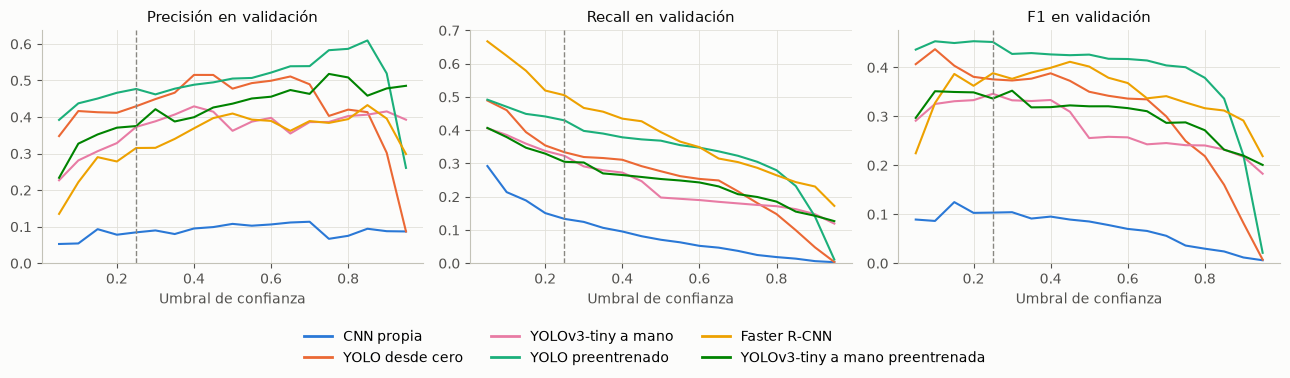

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, columna, titulo in zip(ejes, ["precision", "recall", "F1"], ["Precisión", "Recall", "F1"]):
    for m, curva in curvas_umbral.items():
        ax.plot(curva.umbral, curva[columna], color=COLORES[m], lw=1.5)
    ax.axvline(UMBRAL_CONFIANZA, color=GRIS, ls="--", lw=1)
    ax.set(title=f"{titulo} en validación", xlabel="Umbral de confianza", ylim=(0, None))
guardar(fig, "umbral_val.png", TODOS)

Umbral con el mejor F1 de cada modelo por separado. Sirve de referencia: si los valores difieren, un umbral común favorece a unos modelos más que a otros.

In [8]:
pd.DataFrame({MODELOS[m]: c.loc[c.F1.idxmax()] for m, c in curvas_umbral.items()}).T.round(3)

,umbral,precision,recall,F1
CNN propia,0.15,0.093,0.189,0.125
YOLO desde cero,0.10,0.416,0.460,0.437
YOLOv3-tiny a mano,0.25,0.373,0.323,0.346
YOLO preentrenado,0.20,0.466,0.441,0.453
Faster R-CNN,0.45,0.397,0.427,0.411
YOLOv3-tiny a mano preentrenada,0.30,0.421,0.303,0.352


F1 de cada modelo para cada umbral, y su promedio entre todos.

In [9]:
tabla_f1 = pd.DataFrame({MODELOS[m]: c.set_index("umbral").F1 for m, c in curvas_umbral.items()})
tabla_f1["Promedio"] = tabla_f1.mean(axis=1)
tabla_f1.round(3)

,CNN propia,YOLO desde cero,YOLOv3-tiny a mano,YOLO preentrenado,Faster R-CNN,YOLOv3-tiny a mano preentrenada,Promedio
umbral,,,,,,,
0.05,0.089,0.407,0.291,0.436,0.225,0.297,0.291
0.10,0.086,0.437,0.325,0.453,0.327,0.351,0.330
0.15,0.125,0.403,0.331,0.450,0.387,0.350,0.341
0.20,0.103,0.381,0.333,0.453,0.362,0.349,0.330
0.25,0.103,0.376,0.346,0.452,0.388,0.336,0.334
0.30,0.104,0.373,0.333,0.428,0.377,0.352,0.328
0.35,0.091,0.377,0.331,0.429,0.390,0.318,0.323
0.40,0.095,0.388,0.333,0.427,0.399,0.319,0.327
0.45,0.089,0.373,0.309,0.425,0.411,0.322,0.322


**✍️ Decisión del grupo (D8):** umbral común = 0,25. Razón: ____.

## 4. Métricas con el evaluador común

Se recalculan todas con `evaluar_detecciones`, para que ningún modelo dependa de cómo evaluó su propio cuaderno. Las tablas y figuras de las secciones A, B y C salen de aquí.

In [10]:
def evaluar_modelo(modelo, split):
    """Métricas de un modelo en una partición, con el evaluador y el umbral comunes."""
    return evaluar_detecciones(datos[modelo][split], reales[split], nombres=NOMBRES, umbral_confianza=UMBRAL_CONFIANZA)


metricas = {m: {s: evaluar_modelo(m, s) for s in ("val", "test")} for m in MODELOS}

Control: diferencia en test entre lo recalculado aquí y lo que guardó el cuaderno de cada modelo.

- **mAP:** en YOLO no es cero porque su cuaderno guarda lo que calcula Ultralytics. La celda se detiene si alguna diferencia supera 0,005.
- **Precisión, recall y F1:** en YOLO la diferencia es mayor. Ultralytics usa el umbral con el mejor F1 de cada corrida y asigna precisión 1 a las clases sin detecciones sobre ese umbral. El evaluador común usa un umbral fijo y les asigna 0. Para comparar los modelos valen los valores de este cuaderno.

In [11]:
CLAVES_MAP = ["mAP50", "mAP75", "mAP50_95"]
control = pd.DataFrame({MODELOS[m]: {k: metricas[m]["test"][k] - datos[m]["resumen"][f"test_{k}"] for k in [*CLAVES_MAP, "precision", "recall", "F1"]}
                        for m in MODELOS}).T
assert control[CLAVES_MAP].abs().max().max() < 0.005, "El mAP recalculado no coincide con el del cuaderno del modelo"
control.round(4)

,mAP50,mAP75,mAP50_95,precision,recall,F1
CNN propia,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
YOLO desde cero,0.0014,0.0027,0.0019,-0.0267,-0.0189,-0.0221
YOLOv3-tiny a mano,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
YOLO preentrenado,0.0029,0.0037,0.0031,0.0067,-0.0131,-0.0053
Faster R-CNN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
YOLOv3-tiny a mano preentrenada,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 5. Funciones para las tablas

La misma función sirve para los tres modelos de la sección A y los seis de la sección B.

- **Pesos:** Ultralytics guarda YOLO en float16, y `01`, `02b`, `03b` y `04` guardan en float32. Por eso los archivos no se comparan directamente, y hay una fila que lleva todos a float32 (4 bytes por parámetro).
- **Tiempo:** Faster R-CNN recorre validación una vez más por época, solo para calcular la pérdida. Por eso hay filas sin esa pasada, y los ejes de tiempo de las figuras tampoco la incluyen.
- **Paciencia:** los dos YOLOv8n y las dos YOLOv3-tiny a mano usan 50, y la CNN y Faster R-CNN usan 25. Por eso el tiempo total y las épocas ejecutadas incluyen esperas distintas. El tiempo hasta la mejor época no depende de eso.
- **Parámetros de los dos YOLOv8n:** difieren en 128.256 porque las capas de `cv3` tienen 64 canales en el de desde cero y 80 en el preentrenado.
- **FPS:** los seis modelos se miden en lote 1, con lienzo de 640×640, con el umbral común y en una misma sesión.

In [12]:
ETIQUETAS = {"precision": "Precisión", "recall": "Recall", "F1": "F1", "mAP50": "mAP50", "mAP75": "mAP75", "mAP50_95": "mAP50-95"}
DECIMALES_COSTO = {
    "Tiempo total de entrenamiento (min)": 1, "Tiempo sin la pasada extra (min)": 1,
    "Tiempo hasta la mejor época (min)": 1, "Tiempo hasta la mejor época sin la pasada extra (min)": 1,
    "Tiempo por época (s)": 1, "Tiempo por época sin la pasada extra (s)": 1,
    "Épocas ejecutadas": 0, "Mejor época": 0, "Memoria máxima de GPU (GB)": 2, "Parámetros (millones)": 2,
    "GFLOPs": 1, "Archivo de pesos (MB)": 1, "Pesos en float32 (MB)": 1, "Milisegundos por imagen": 1, "FPS": 1,
}


def tabla_desempeno(modelos, split="test"):
    """Precisión, recall, F1 y mAP de cada modelo en una partición."""
    return pd.DataFrame({MODELOS[m]: {e: metricas[m][split][k] for k, e in ETIQUETAS.items()} for m in modelos}).T


def tabla_detalle_precision(modelos):
    """Clases con detecciones sobre el umbral y precisión sin promediar por clase, en test."""
    filas = {MODELOS[m]: {"Clases con detecciones": metricas[m]["test"]["clases_con_detecciones"],
                          "Precisión micro": metricas[m]["test"]["precision_micro"]} for m in modelos}
    return pd.DataFrame(filas).T.astype({"Clases con detecciones": int})


def historial_sin_pasada(modelo):
    """Historial de un modelo con el tiempo acumulado sin la pasada extra por validación, que solo hace Faster R-CNN."""
    historial = datos[modelo]["historial"]
    if modelo != "faster_rcnn":
        return historial
    rutas = [c / modelo / "historial_completo.csv" for c in (CARPETA_RUNS / "reales", RAIZ / "entrenamientos")]
    pasada = pd.read_csv(next(r for r in rutas if r.exists())).set_index("epoca").segundos_perdida_val
    return historial.assign(tiempo_s=historial.tiempo_s - historial.epoca.map(pasada.cumsum()))


def tabla_costo(modelos):
    """Tiempo, memoria, tamaño y velocidad de cada modelo, con lo que midió su cuaderno (valores sin redondear)."""
    columnas = {}
    for m in modelos:
        resumen, historial = datos[m]["resumen"], datos[m]["historial"]
        sin_pasada = historial_sin_pasada(m)
        es_mejor = historial.epoca == resumen["mejor_epoca"]
        pasada_total_s = historial.tiempo_s.iloc[-1] - sin_pasada.tiempo_s.iloc[-1]
        columnas[MODELOS[m]] = dict(zip(DECIMALES_COSTO, [
            resumen["tiempo_entrenamiento_min"], resumen["tiempo_entrenamiento_min"] - pasada_total_s / 60,
            historial.tiempo_s[es_mejor].iloc[0] / 60, sin_pasada.tiempo_s[es_mejor].iloc[0] / 60,
            resumen["tiempo_por_epoca_s"], resumen["tiempo_por_epoca_s"] - pasada_total_s / resumen["epocas_ejecutadas"],
            resumen["epocas_ejecutadas"], resumen["mejor_epoca"], resumen["memoria_gpu_max_GB"], resumen["parametros_M"],
            resumen["GFLOPs"], resumen["tamano_pesos_MB"], resumen["parametros_M"] * 4, resumen["ms_total_por_imagen"], resumen["FPS"],
        ]))
    return pd.DataFrame(columnas)


def mostrar_costo(tabla):
    """Devuelve la tabla de costos como texto, con los decimales que corresponden a cada fila."""
    return tabla.apply(lambda fila: fila.map(lambda v: f"{v:.{DECIMALES_COSTO[fila.name]}f}"), axis=1)


def tabla_por_frecuencia(modelos):
    """AP50 medio de test según cuántas instancias tiene cada clase en test."""
    grupos = {"100 o más instancias": (100, np.inf), "10 a 99 instancias": (10, 100), "Menos de 10 instancias": (0, 10)}
    filas = {}
    for grupo, (desde, hasta) in grupos.items():
        selecciones = {m: metricas[m]["test"]["por_clase"].query("@desde <= instancias < @hasta") for m in modelos}
        filas[grupo] = {"Clases": len(selecciones[modelos[0]]), **{MODELOS[m]: s.AP50.mean() for m, s in selecciones.items()}}
    return pd.DataFrame(filas).T.astype({"Clases": int})


def tabla_ap_por_clase(modelos):
    """AP50 de test por clase (filas) y modelo (columnas), de la clase con más instancias a la que tiene menos."""
    orden = metricas[modelos[0]]["test"]["por_clase"].sort_values("instancias", ascending=False)
    tabla = pd.DataFrame({MODELOS[m]: metricas[m]["test"]["por_clase"].set_index("clase").AP50 for m in modelos}).loc[orden.clase]
    tabla.index = [f"{c} ({n})" for c, n in zip(orden.clase, orden.instancias)]
    return tabla


def tabla_mejor_modelo():
    """Ordena los modelos por mAP50-95 de validación."""
    filas = {MODELOS[m]: {"mAP50-95 en val": metricas[m]["val"]["mAP50_95"], "mAP50 en val": metricas[m]["val"]["mAP50"],
                          "mAP50-95 en test": metricas[m]["test"]["mAP50_95"], "mAP50 en test": metricas[m]["test"]["mAP50"],
                          "FPS": datos[m]["resumen"]["FPS"]} for m in MODELOS}
    return pd.DataFrame(filas).T.sort_values("mAP50-95 en val", ascending=False)

Funciones para medir cuánto se solapan las cajas de cada modelo, cuántas deja por objeto y qué cambia con un límite de IoU más estricto en el NMS.

In [13]:
def aplicar_nms(detecciones, iou_maximo):
    """Vuelve a aplicar el NMS por clase a detecciones guardadas, con otro límite de IoU."""
    quedan = []
    for _, g in detecciones.groupby("id"):
        indices = batched_nms(torch.tensor(g[COLUMNAS_CAJA].to_numpy(float)), torch.tensor(g.confianza.to_numpy()),
                              torch.tensor(g.clase_id.to_numpy()), iou_maximo)
        quedan.extend(g.index[indices.numpy()])
    return detecciones.loc[quedan].reset_index(drop=True)


def mayor_iou_con_objetos(cajas, objetos):
    """Para cada caja de una imagen, su mayor IoU con un objeto real, sin mirar la clase (0 si la imagen no tiene objetos)."""
    if objetos is None:
        return np.zeros(len(cajas))
    return iou(cajas[COLUMNAS_CAJA].to_numpy(float), objetos[COLUMNAS_CAJA].to_numpy(float)).max(1)


def solape_en_imagen(g, ancho, alto):
    """Cajas de una imagen con otra de su clase encima, pares de igual clase, pares sobre el límite del NMS y cuántos de ellos tocan el borde."""
    cajas, clases = g[COLUMNAS_CAJA].to_numpy(float), g.clase_id.to_numpy()
    misma_clase = np.triu(clases[:, None] == clases[None, :], 1)   # cada par una sola vez, sin la diagonal
    matriz = iou(cajas, cajas) * misma_clase
    con_vecina = ((matriz >= IOU_SOLAPE).any(0) | (matriz >= IOU_SOLAPE).any(1)).sum()
    a, b = np.nonzero(matriz >= IOU_NMS)
    en_borde = (cajas[:, 0] <= 0.5) | (cajas[:, 1] <= 0.5) | (cajas[:, 2] >= ancho - 0.5) | (cajas[:, 3] >= alto - 0.5)
    return con_vecina, misma_clase.sum(), len(a), (en_borde[a] | en_borde[b]).sum()


def medir_cajas(detecciones, split):
    """Solape entre las detecciones sobre el umbral, su ubicación respecto de los objetos reales y la más segura de cada imagen."""
    objetos = dict(tuple(reales[split].groupby("id")))
    sobre_umbral = detecciones[detecciones.confianza >= UMBRAL_CONFIANZA]
    solape, mejor_iou = [], []
    for id_img, g in sobre_umbral.groupby("id"):
        solape.append(solape_en_imagen(g, *Image.open(DIR_DATASET / "images" / split / f"{id_img}.jpg").size))
        mejor_iou.append(mayor_iou_con_objetos(g, objetos.get(id_img)))
    con_vecina, pares, sobre_limite, en_borde = np.sum(solape, axis=0)
    mejor_iou = np.concatenate(mejor_iou)
    mas_seguras = detecciones.loc[detecciones.groupby("id").confianza.idxmax()]
    aciertos = sum(mayor_iou_con_objetos(g, objetos.get(i)).max() >= IOU_SOBRE_OBJETO for i, g in mas_seguras.groupby("id"))
    return {
        "Cajas por imagen": len(sobre_umbral) / len(particion[split]),
        "Con otra de su clase encima": con_vecina / len(sobre_umbral),
        "Pares de igual clase": pares,
        "Pares sobre el límite del NMS": sobre_limite,
        "De ellos, con una caja en el borde": en_borde,
        "Sobre un objeto": (mejor_iou >= IOU_SOBRE_OBJETO).mean(),
        "Rozan un objeto": ((mejor_iou >= IOU_ROZA_OBJETO) & (mejor_iou < IOU_SOBRE_OBJETO)).mean(),
        "En nada": (mejor_iou < IOU_ROZA_OBJETO).mean(),
        "Imágenes con la más segura sobre un objeto": aciertos / len(objetos),
    }


def tabla_solape_cajas(split="val"):
    """Solape y ubicación de las cajas de cada modelo, con el NMS del protocolo común."""
    enteras = ["Pares de igual clase", "Pares sobre el límite del NMS", "De ellos, con una caja en el borde"]
    return pd.DataFrame({MODELOS[m]: medir_cajas(datos[m][split], split) for m in TODOS}).T.astype({c: int for c in enteras})


def cajas_de_cada_objeto(detecciones, cajas_reales):
    """Para cada objeto real, cuántas detecciones sobre el umbral lo cubren, sin mirar la clase."""
    sobre_umbral = dict(tuple(detecciones[detecciones.confianza >= UMBRAL_CONFIANZA].groupby("id")))
    cuentas = []
    for id_img, objetos in cajas_reales.groupby("id"):
        cajas = sobre_umbral.get(id_img)
        if cajas is None:
            cuentas.append(np.zeros(len(objetos), int))
        else:
            cuentas.append((iou(objetos[COLUMNAS_CAJA].to_numpy(float), cajas[COLUMNAS_CAJA].to_numpy(float)) >= IOU_SOLAPE).sum(1))
    return np.concatenate(cuentas)


def tabla_limites_nms(split="val"):
    """Cajas por objeto y métricas de cada modelo, con el NMS del protocolo y con límites más estrictos."""
    filas = {}
    for m in TODOS:
        for limite in [IOU_NMS, *IOUS_NMS_ESTRICTOS]:
            detecciones = datos[m][split] if limite == IOU_NMS else aplicar_nms(datos[m][split], limite)
            cuentas = cajas_de_cada_objeto(detecciones, reales[split])
            con_caja = cuentas[cuentas >= 1]
            evaluacion = evaluar_detecciones(detecciones, reales[split], umbral_confianza=UMBRAL_CONFIANZA)
            filas[MODELOS[m], limite] = {
                "Cajas por imagen": (detecciones.confianza >= UMBRAL_CONFIANZA).sum() / len(particion[split]),
                "Objetos con caja": len(con_caja) / len(cuentas),
                "Cajas por objeto con caja": con_caja.mean(),
                "Objetos con caja que tienen solo una": (con_caja == 1).mean(),
                **{ETIQUETAS[k]: evaluacion[k] for k in ("mAP50", "mAP50_95", "recall", "F1")},
                "Precisión micro": evaluacion["precision_micro"],
            }
    return pd.DataFrame(filas).T.rename_axis(["Modelo", "IoU del NMS"])

## 6. Funciones para las figuras

Cada figura tiene su función, que recibe la lista de modelos y el nombre del archivo. Primero, las de desempeño, curvas de validación y curva precisión-recall.

In [14]:
def grafico_desempeno(modelos, nombre):
    """Barras agrupadas con la precisión, el recall, el F1 y el mAP de test de cada modelo."""
    tabla = tabla_desempeno(modelos)
    fig, ax = plt.subplots(figsize=(1.6 * len(ETIQUETAS), 3.8))
    ancho = 0.8 / len(modelos)
    for i, m in enumerate(modelos):
        posiciones = np.arange(len(ETIQUETAS)) - 0.4 + (i + 0.5) * ancho
        ax.bar(posiciones, tabla.loc[MODELOS[m]], ancho, color=COLORES[m], edgecolor=FONDO, linewidth=1)
    ax.set_xticks(range(len(ETIQUETAS)), list(ETIQUETAS.values()))
    ax.set(title=f"Desempeño en test (umbral {UMBRAL_CONFIANZA} para precisión, recall y F1)", ylabel="Valor")
    ax.grid(axis="x", visible=False)
    guardar(fig, nombre, modelos)


def grafico_curvas(modelos, nombre):
    """mAP50-95 de validación por época y según el tiempo sin la pasada extra; el punto marca la mejor época."""
    fig, (ax_epoca, ax_tiempo) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for m in modelos:
        h = historial_sin_pasada(m)
        mejor = h[h.epoca == datos[m]["resumen"]["mejor_epoca"]].iloc[0]
        ax_epoca.plot(h.epoca, h.val_mAP50_95, color=COLORES[m], lw=1.5)
        ax_epoca.scatter(mejor.epoca, mejor.val_mAP50_95, color=COLORES[m], s=40, zorder=3, ec=FONDO)
        ax_tiempo.plot(h.tiempo_s / 60, h.val_mAP50_95, color=COLORES[m], lw=1.5)
        ax_tiempo.scatter(mejor.tiempo_s / 60, mejor.val_mAP50_95, color=COLORES[m], s=40, zorder=3, ec=FONDO)
    ax_epoca.set(title="mAP50-95 de validación por época", xlabel="Época", ylabel="mAP50-95")
    ax_epoca.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax_tiempo.set(title="mAP50-95 de validación según el tiempo", xlabel="Tiempo de entrenamiento sin la pasada extra (min)")
    guardar(fig, nombre, modelos)


def grafico_pr(modelos, nombre):
    """Curva precisión-recall de test, promediada entre clases, con IoU 0,5."""
    fig, ax = plt.subplots(figsize=(5.4, 4.4))
    for m in modelos:
        curva = metricas[m]["test"]["curva_pr"]
        ax.plot(curva.recall, curva.precision, color=COLORES[m], lw=1.5)
    ax.set(title="Curva precisión-recall en test (IoU 0,5)", xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1))
    guardar(fig, nombre, modelos)

Mapa de calor del AP50 por clase y gráfico del compromiso entre el mAP50-95, el tiempo de entrenamiento y los FPS.

In [15]:
def grafico_ap_por_clase(modelos, nombre):
    """Mapa de calor del AP50 de test; entre paréntesis, las instancias de cada clase en test."""
    tabla = tabla_ap_por_clase(modelos)
    fig, ax = plt.subplots(figsize=(3 + 1.5 * len(modelos), 0.3 * len(tabla) + 1.2))
    imagen = ax.imshow(tabla.to_numpy(), cmap=MAPA_AP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(tabla.shape[1]), tabla.columns)
    ax.set_yticks(range(tabla.shape[0]), tabla.index)
    ax.tick_params(length=0)
    ax.grid(False)
    for (i, j), valor in np.ndenumerate(tabla.to_numpy()):
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color="white" if valor >= 0.4 else TINTA)
    ax.set_title("AP50 por clase en test")
    fig.colorbar(imagen, ax=ax, label="AP50", fraction=0.04, pad=0.02)
    guardar(fig, nombre)


def grafico_compromiso(modelos, nombre):
    """mAP50-95 de test frente al tiempo de entrenamiento sin la pasada extra y frente a los FPS, con cada modelo rotulado."""
    costo = tabla_costo(modelos)
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    paneles = [("Tiempo sin la pasada extra (min)", "Tiempo de entrenamiento sin la pasada extra (min)", "el tiempo de entrenamiento"), ("FPS", "FPS (lote 1)", "los FPS")]
    for ax, (fila, etiqueta, texto) in zip(ejes, paneles):
        for m in modelos:
            x, y = costo.loc[fila, MODELOS[m]], metricas[m]["test"]["mAP50_95"]
            ax.scatter(x, y, color=COLORES[m], s=70, zorder=3, ec=FONDO)
            ax.annotate(MODELOS[m], (x, y), xytext=(8, 5), textcoords="offset points", fontsize=9, color=TINTA)
        ax.set_xlim(0, 1.25 * costo.loc[fila].max())
        ax.set(title=f"mAP50-95 de test según {texto}", xlabel=etiqueta)
    ejes[0].set(ylabel="mAP50-95 en test", ylim=(-0.01, 1.15 * max(metricas[m]["test"]["mAP50_95"] for m in modelos)))
    guardar(fig, nombre, modelos)

Dibujo de las cajas y figura de ejemplos, con las imágenes de `IDS_EJEMPLOS` para todos los modelos.

In [16]:
def dibujar_cajas(ax, imagen, cajas, color, titulo, etiquetas=True):
    """Muestra una imagen con sus cajas (tabla con clase_id, x1, y1, x2, y2 y, si la hay, confianza)."""
    ax.imshow(imagen)
    for fila in cajas.itertuples():
        ax.add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1, fill=False, ec=color, lw=1.5))
        if etiquetas:
            texto = NOMBRES[fila.clase_id] + (f" {fila.confianza:.2f}" if hasattr(fila, "confianza") else "")
            ax.text(fila.x1, fila.y1, texto, color=TINTA, fontsize=6, va="top" if fila.y1 < 0.05 * imagen.height else "bottom",
                    bbox=dict(fc=color, ec="none", pad=1), clip_on=True)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def grafico_ejemplos(modelos, nombre):
    """Las mismas imágenes de test con las cajas reales y las detecciones de cada modelo sobre el umbral común."""
    fig, ejes = plt.subplots(len(IDS_EJEMPLOS), len(modelos) + 1, figsize=(3.1 * (len(modelos) + 1), 1.9 * len(IDS_EJEMPLOS) + 0.3), squeeze=False)
    for n_fila, (fila, id_img) in enumerate(zip(ejes, IDS_EJEMPLOS)):
        imagen = Image.open(DIR_DATASET / "images" / "test" / f"{id_img}.jpg").convert("RGB")
        dibujar_cajas(fila[0], imagen, reales["test"].query("id == @id_img"), GRIS, "Cajas reales" if n_fila == 0 else "")
        for ax, m in zip(fila[1:], modelos):
            detecciones = datos[m]["test"].query("id == @id_img and confianza >= @UMBRAL_CONFIANZA")
            dibujar_cajas(ax, imagen, detecciones, COLORES[m], MODELOS[m] if n_fila == 0 else "")
    guardar(fig, nombre)

Figura de las imágenes de ejemplo con cada límite de IoU del NMS.

In [17]:
def dibujar_panel_nms(ax, imagen, cajas, color, titulo):
    """Dibuja cajas sin etiquetas, para que se distingan cuando se solapan, e indica cuántas son."""
    dibujar_cajas(ax, imagen, cajas, color, titulo, etiquetas=False)
    ax.text(0.01, 0.97, f"{len(cajas)} caja{'s' if len(cajas) != 1 else ''}", transform=ax.transAxes, va="top", fontsize=7,
            color=TINTA, bbox=dict(fc=FONDO, ec="none", pad=1))


def grafico_limites_nms(modelo, nombre):
    """Las imágenes de ejemplo con las cajas reales y las detecciones de un modelo con cada límite de IoU del NMS."""
    limites = [IOU_NMS, *IOUS_NMS_ESTRICTOS]
    fig, ejes = plt.subplots(len(IDS_EJEMPLOS), len(limites) + 1, figsize=(3.1 * (len(limites) + 1), 1.9 * len(IDS_EJEMPLOS) + 0.3), squeeze=False)
    for n_fila, (fila, id_img) in enumerate(zip(ejes, IDS_EJEMPLOS)):
        imagen = Image.open(DIR_DATASET / "images" / "test" / f"{id_img}.jpg").convert("RGB")
        dibujar_panel_nms(fila[0], imagen, reales["test"].query("id == @id_img"), GRIS, "Cajas reales" if n_fila == 0 else "")
        detecciones = datos[modelo]["test"].query("id == @id_img and confianza >= @UMBRAL_CONFIANZA")
        for ax, limite in zip(fila[1:], limites):
            cajas = detecciones if limite == IOU_NMS else aplicar_nms(detecciones, limite)
            titulo = f"{MODELOS[modelo]}, NMS con IoU {limite}".replace(".", ",") if n_fila == 0 else ""
            dibujar_panel_nms(ax, imagen, cajas, COLORES[modelo], titulo)
    guardar(fig, nombre)

## A. Modelos desde cero: CNN propia, YOLOv8n y YOLOv3-tiny a mano (ítem 1.4)

Primero, las métricas de detección en test, con el umbral común.

In [18]:
tabla_desempeno(MODELOS_DESDE_CERO).round(3)

,Precisión,Recall,F1,mAP50,mAP75,mAP50-95
CNN propia,0.075,0.129,0.095,0.074,0.002,0.020
YOLO desde cero,0.535,0.386,0.448,0.436,0.229,0.248
YOLOv3-tiny a mano,0.423,0.330,0.371,0.380,0.090,0.143


La precisión de la tabla anterior se promedia entre clases, y una clase sin detecciones sobre el umbral aporta 0. Por eso esta tabla agrega la precisión sin promediar por clase (precisión micro) y cuántas clases con cajas reales tienen alguna detección sobre el umbral.

In [19]:
tabla_detalle_precision(MODELOS_DESDE_CERO).round(3)

,Clases con detecciones,Precisión micro
CNN propia,15,0.115
YOLO desde cero,22,0.685
YOLOv3-tiny a mano,20,0.592


Las métricas de la tabla de desempeño en una figura, para las diapositivas.

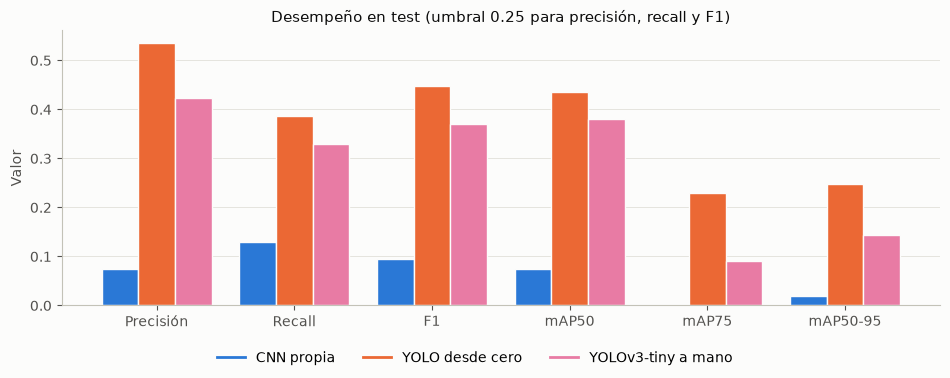

In [20]:
grafico_desempeno(MODELOS_DESDE_CERO, "a_desempeno.png")

Costo de cada modelo: tiempo de entrenamiento, memoria, tamaño y velocidad.

In [21]:
mostrar_costo(tabla_costo(MODELOS_DESDE_CERO))

,CNN propia,YOLO desde cero,YOLOv3-tiny a mano
Tiempo total de entrenamiento (min),80.1,80.0,90.9
Tiempo sin la pasada extra (min),80.1,80.0,90.9
Tiempo hasta la mejor época (min),49.5,66.4,71.5
Tiempo hasta la mejor época sin la pasada extra (min),49.5,66.4,71.5
Tiempo por época (s),73.9,16.3,23.2
Tiempo por época sin la pasada extra (s),73.9,16.3,23.2
Épocas ejecutadas,65,294,235
Mejor época,40,244,185
Memoria máxima de GPU (GB),3.27,2.59,2.75
Parámetros (millones),28.65,3.02,8.73


Evolución del mAP50-95 de validación durante el entrenamiento. El panel derecho usa el tiempo, porque los modelos no tardan lo mismo por época.

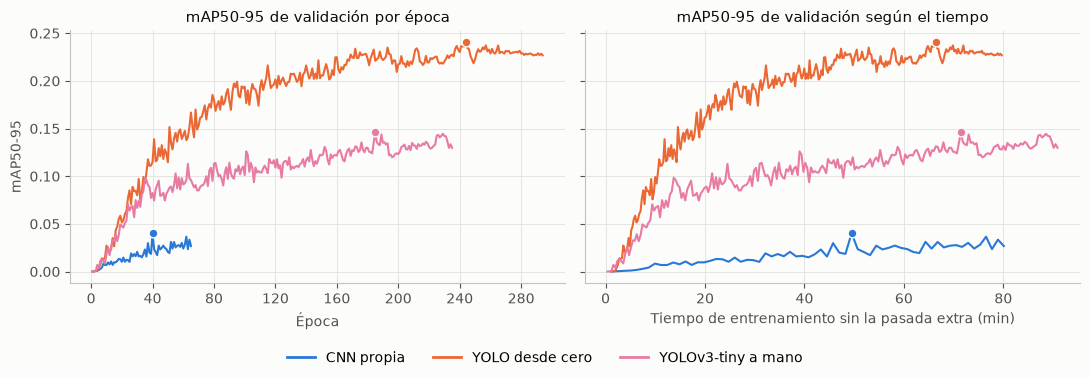

In [22]:
grafico_curvas(MODELOS_DESDE_CERO, "a_curvas_val.png")

Curva precisión-recall de test: muestra el desempeño para todos los umbrales, no solo para el común.

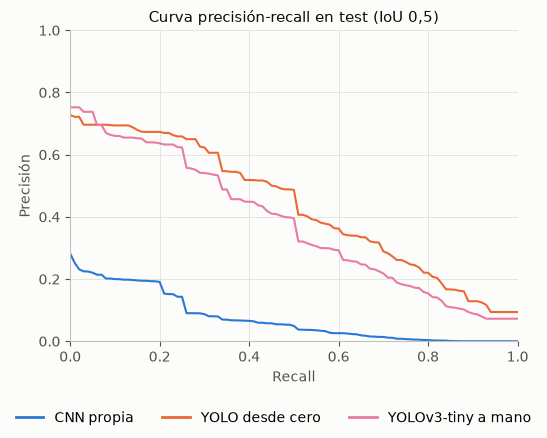

In [23]:
grafico_pr(MODELOS_DESDE_CERO, "a_curva_pr.png")

AP50 por clase en test. El mAP es el promedio de estos valores, así que cada clase pesa lo mismo aunque tenga pocas instancias.

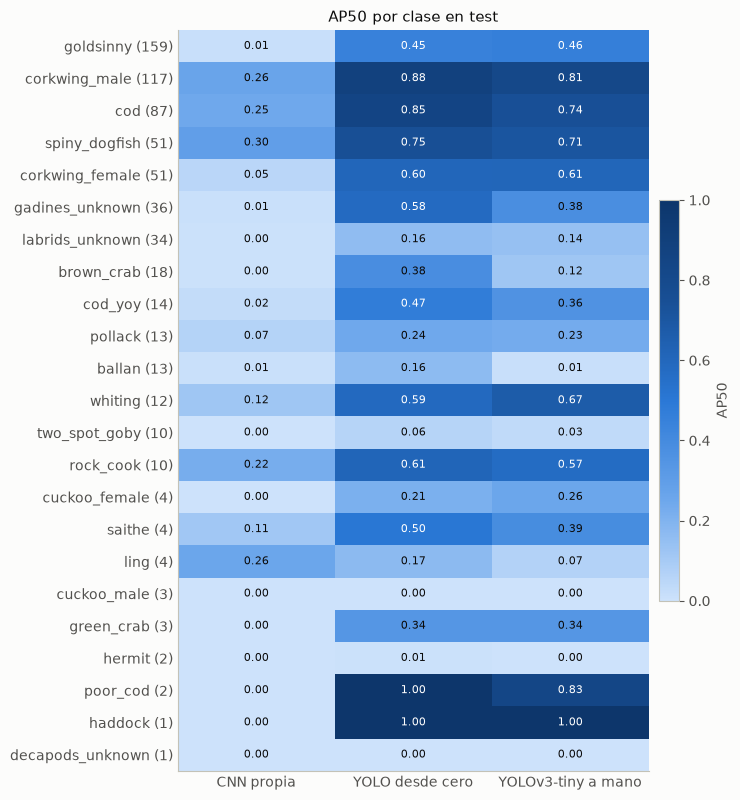

In [24]:
grafico_ap_por_clase(MODELOS_DESDE_CERO, "a_ap_por_clase.png")

Las mismas imágenes de test con las cajas reales y las detecciones de cada modelo.

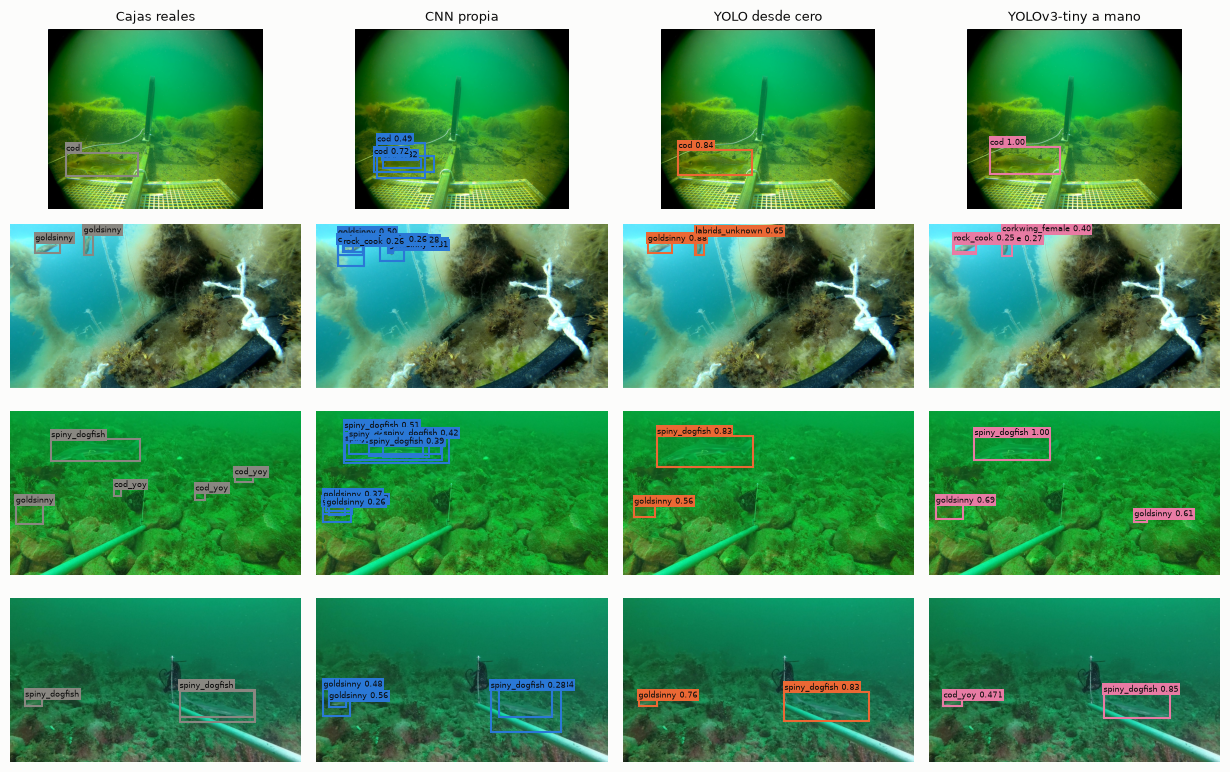

In [25]:
grafico_ejemplos(MODELOS_DESDE_CERO, "a_ejemplos.png")

### ✍️ Análisis de la sección A (completar por el grupo)

-

## B. Los seis modelos: desde cero y preentrenados (ítem 2.4)

Métricas de detección en test, con el umbral común.

In [26]:
tabla_desempeno(TODOS).round(3)

,Precisión,Recall,F1,mAP50,mAP75,mAP50-95
CNN propia,0.075,0.129,0.095,0.074,0.002,0.020
YOLO desde cero,0.535,0.386,0.448,0.436,0.229,0.248
YOLOv3-tiny a mano,0.423,0.330,0.371,0.380,0.090,0.143
YOLO preentrenado,0.553,0.439,0.489,0.476,0.380,0.342
Faster R-CNN,0.304,0.428,0.356,0.433,0.302,0.282
YOLOv3-tiny a mano preentrenada,0.397,0.333,0.362,0.371,0.114,0.152


La precisión de la tabla anterior se promedia entre clases, y una clase sin detecciones sobre el umbral aporta 0. Por eso esta tabla agrega la precisión sin promediar por clase (precisión micro) y cuántas clases con cajas reales tienen alguna detección sobre el umbral.

In [27]:
tabla_detalle_precision(TODOS).round(3)

,Clases con detecciones,Precisión micro
CNN propia,15,0.115
YOLO desde cero,22,0.685
YOLOv3-tiny a mano,20,0.592
YOLO preentrenado,22,0.757
Faster R-CNN,20,0.369
YOLOv3-tiny a mano preentrenada,19,0.606


Las métricas de la tabla de desempeño en una figura, para las diapositivas.

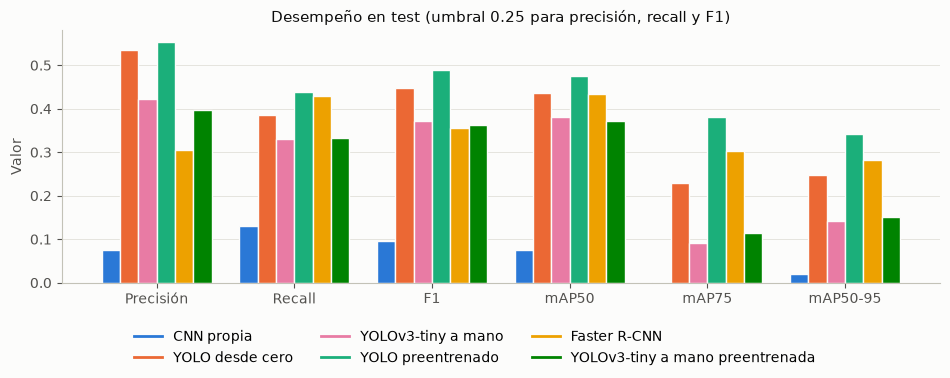

In [28]:
grafico_desempeno(TODOS, "b_desempeno.png")

Costo de cada modelo: tiempo de entrenamiento, memoria, tamaño y velocidad.

In [29]:
mostrar_costo(tabla_costo(TODOS))

,CNN propia,YOLO desde cero,YOLOv3-tiny a mano,YOLO preentrenado,Faster R-CNN,YOLOv3-tiny a mano preentrenada
Tiempo total de entrenamiento (min),80.1,80.0,90.9,88.7,226.4,68.5
Tiempo sin la pasada extra (min),80.1,80.0,90.9,88.7,215.5,68.5
Tiempo hasta la mejor época (min),49.5,66.4,71.5,80.4,130.5,49.5
Tiempo hasta la mejor época sin la pasada extra (min),49.5,66.4,71.5,80.4,124.3,49.5
Tiempo por época (s),73.9,16.3,23.2,17.7,230.2,23.0
Tiempo por época sin la pasada extra (s),73.9,16.3,23.2,17.7,219.1,23.0
Épocas ejecutadas,65,294,235,300,59,179
Mejor época,40,244,185,272,34,129
Memoria máxima de GPU (GB),3.27,2.59,2.75,2.67,3.69,2.75
Parámetros (millones),28.65,3.02,8.73,3.14,43.39,8.73


Relación entre el mAP50-95 de test y lo que cuesta obtenerlo: tiempo de entrenamiento y velocidad de inferencia.

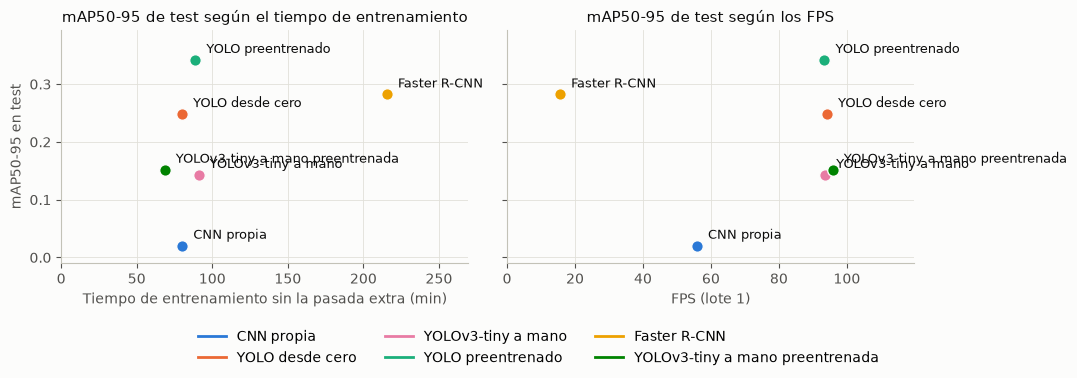

In [30]:
grafico_compromiso(TODOS, "b_mAP_tiempo_FPS.png")

Evolución del mAP50-95 de validación durante el entrenamiento.

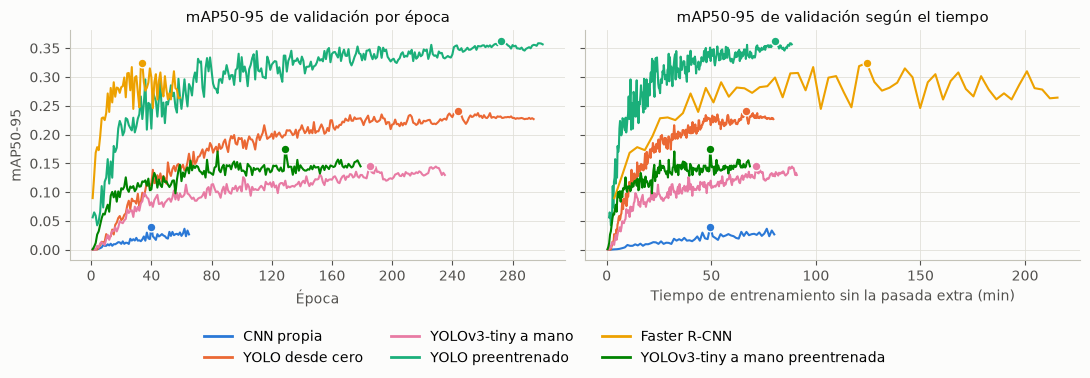

In [31]:
grafico_curvas(TODOS, "b_curvas_val.png")

Curva precisión-recall de test.

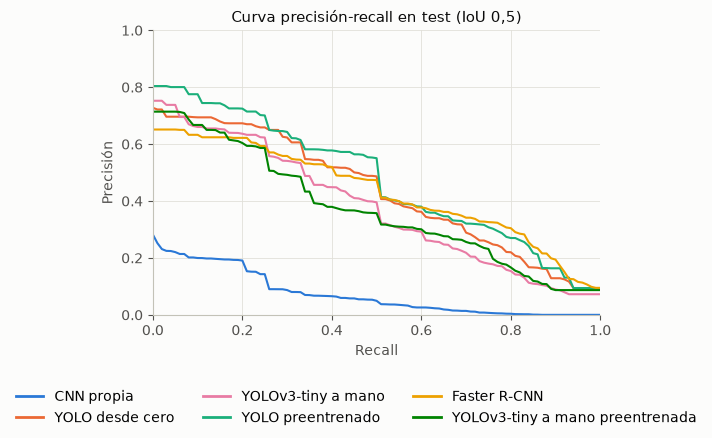

In [32]:
grafico_pr(TODOS, "b_curva_pr.png")

AP50 por clase en test para los seis modelos.

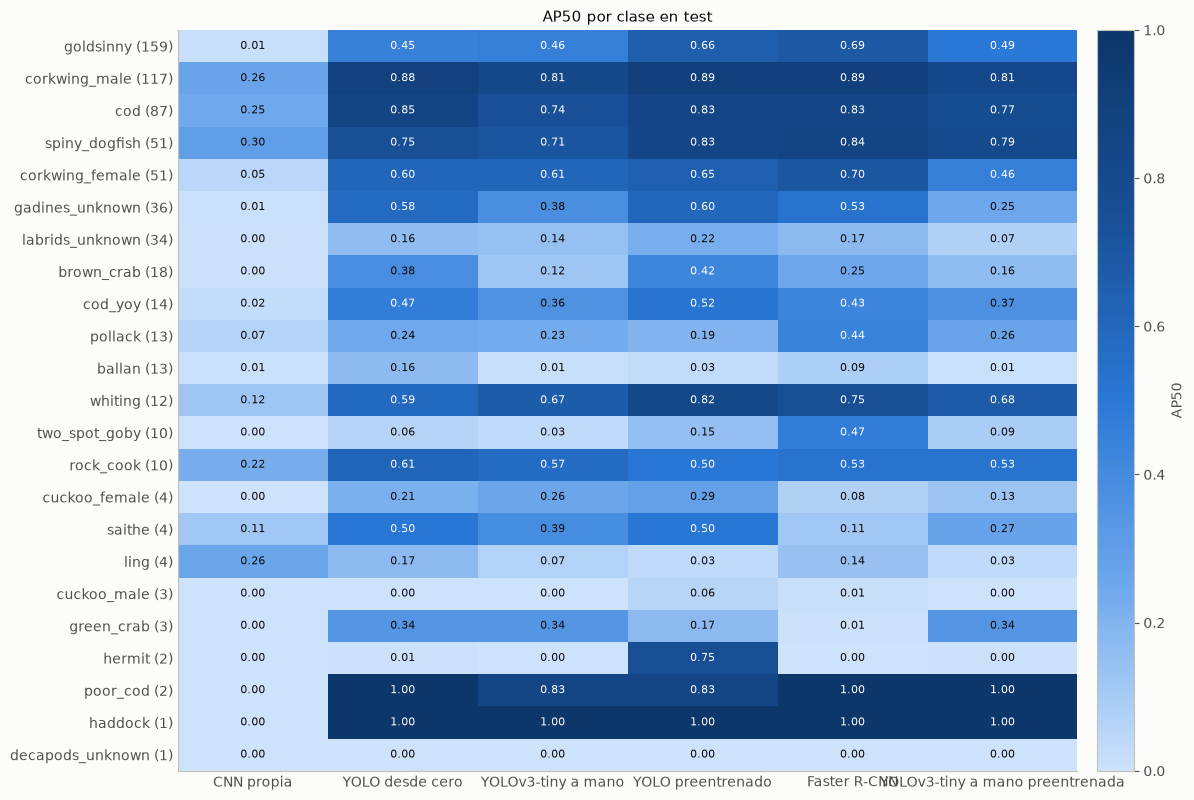

In [33]:
grafico_ap_por_clase(TODOS, "b_ap_por_clase.png")

AP50 medio según cuántas instancias tiene cada clase. Una clase con muy pocas instancias puede mover mucho el mAP, porque cada clase pesa lo mismo en el promedio.

In [34]:
tabla_por_frecuencia(TODOS).round(3)

,Clases,CNN propia,YOLO desde cero,YOLOv3-tiny a mano,YOLO preentrenado,Faster R-CNN,YOLOv3-tiny a mano preentrenada
100 o más instancias,2,0.139,0.667,0.637,0.775,0.789,0.653
10 a 99 instancias,12,0.088,0.455,0.382,0.480,0.502,0.371
Menos de 10 instancias,9,0.042,0.359,0.321,0.404,0.261,0.308


Las mismas imágenes de la sección A, ahora con los seis modelos.

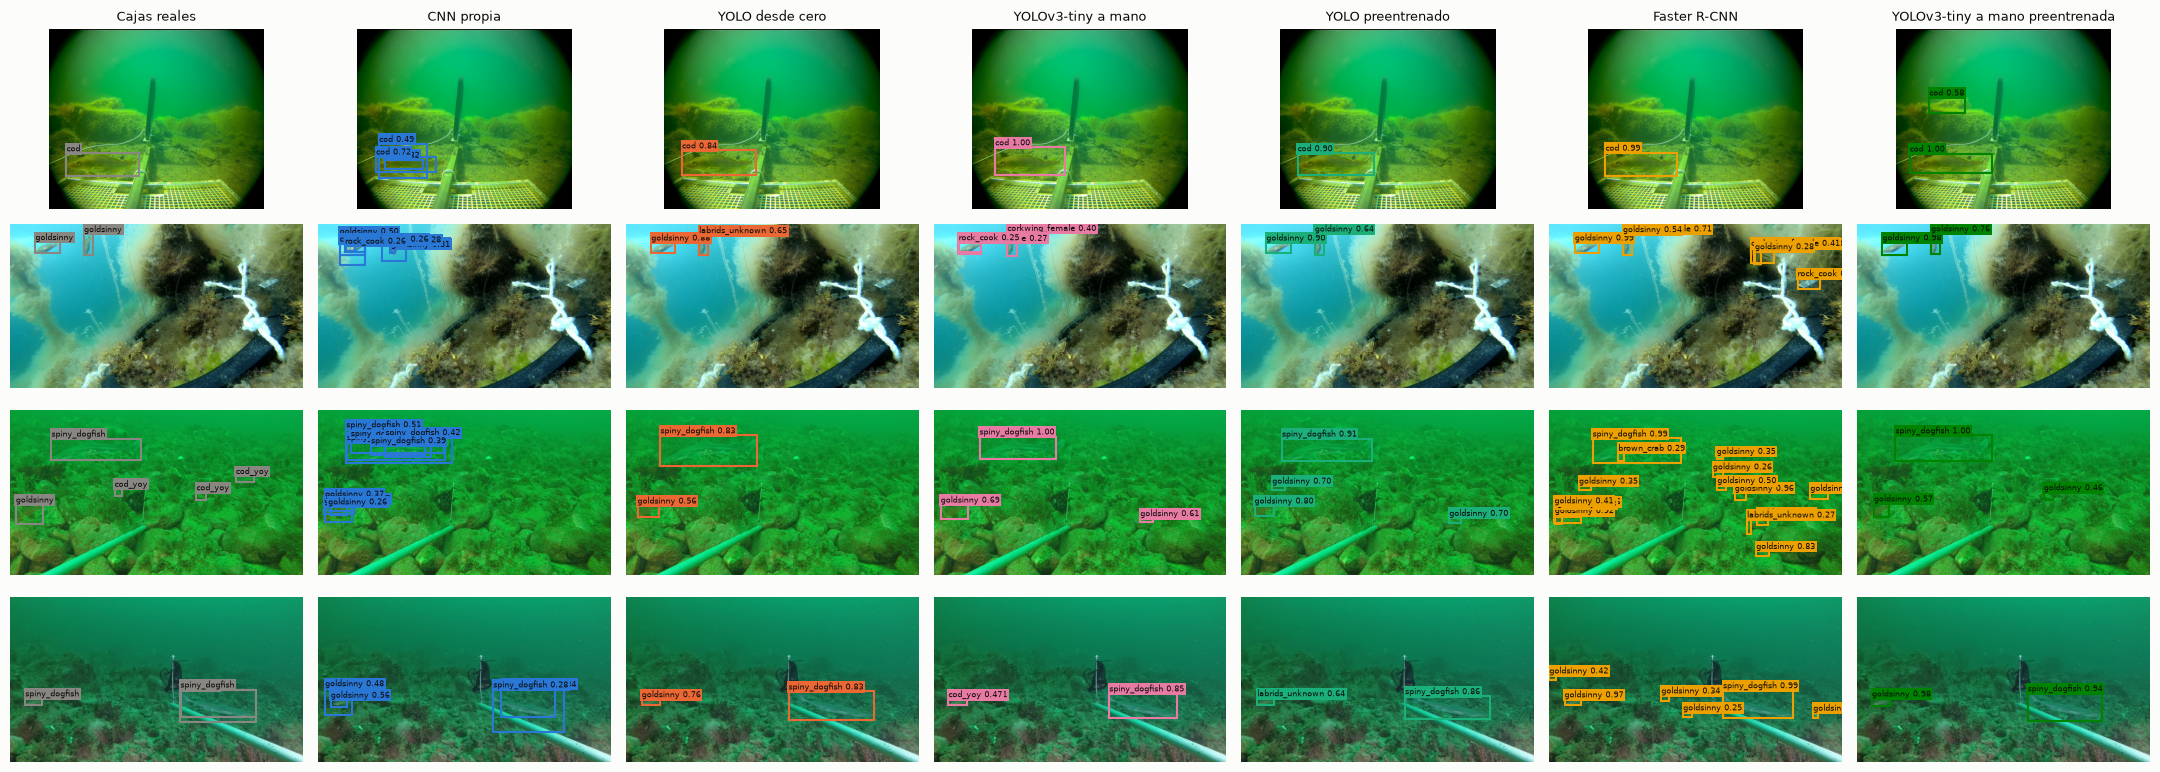

In [35]:
grafico_ejemplos(TODOS, "b_ejemplos.png")

**Solape y ubicación de las cajas.** Complementa la figura anterior. Se mide en validación, con el protocolo común (NMS con IoU 0,5) y con las cajas sobre el umbral:
- *Con otra de su clase encima*: fracción de cajas que tienen otra de igual clase con IoU ≥ 0,3.
- *Pares sobre el límite del NMS*: pares de igual clase con IoU ≥ 0,5. El NMS no debería dejar ninguno, pero se aplica antes de pasar las cajas a la imagen original y recortarlas a su borde, y ese recorte puede subir el IoU. Por eso se indica cuántos tienen una caja en el borde.
- *Sobre un objeto*, *Rozan un objeto* y *En nada*: fracción de cajas según su mayor IoU con un objeto real, sin mirar la clase (≥ 0,5; entre 0,1 y 0,5; < 0,1).
- *Imágenes con la más segura sobre un objeto*: fracción de imágenes cuya detección de mayor confianza, sobre o bajo el umbral, tiene IoU ≥ 0,5 con un objeto real.

In [36]:
tabla_solape_val = tabla_solape_cajas()
tabla_solape_val.round(3)

,Cajas por imagen,Con otra de su clase encima,Pares de igual clase,Pares sobre el límite del NMS,"De ellos, con una caja en el borde",Sobre un objeto,Rozan un objeto,En nada,Imágenes con la más segura sobre un objeto
CNN propia,5.316,0.586,8746,9,8,0.218,0.509,0.274,0.402
YOLO desde cero,1.658,0.040,301,0,0,0.856,0.072,0.072,0.870
YOLOv3-tiny a mano,1.777,0.112,420,1,1,0.776,0.136,0.088,0.844
YOLO preentrenado,1.837,0.024,356,0,0,0.868,0.047,0.085,0.920
Faster R-CNN,4.113,0.099,2052,0,0,0.523,0.061,0.416,0.914
YOLOv3-tiny a mano preentrenada,1.801,0.111,341,1,1,0.779,0.113,0.109,0.887


**Límite de IoU del NMS.** Muestra qué cambiaría con un NMS más estricto, sin cambiar el protocolo: todas las demás tablas de este cuaderno siguen con IoU 0,5 en todos los modelos. Se vuelve a aplicar el NMS a las detecciones guardadas y se mide en validación, porque es una comprobación del protocolo. Un objeto *tiene caja* si alguna detección sobre el umbral lo cubre con IoU ≥ 0,3, sin mirar la clase. Las métricas son las del evaluador común.

In [37]:
tabla_nms_val = tabla_limites_nms()
tabla_nms_val.round(3)

Cajas por imagen  \
Modelo                          IoU del NMS                     
CNN propia                      0.5                     5.316   
                                0.3                     3.598   
                                0.1                     2.485   
YOLO desde cero                 0.5                     1.658   
                                0.3                     1.625   
                                0.1                     1.601   
YOLOv3-tiny a mano              0.5                     1.777   
                                0.3                     1.681   
                                0.1                     1.651   
YOLO preentrenado               0.5                     1.837   
                                0.3                     1.817   
                                0.1                     1.784   
Faster R-CNN                    0.5                     4.113   
                                0.3                     3.914   
                                0.1                     3.831   
YOLOv3-tiny a mano preentrenada 0.5                     1.801   
                                0.3                     1.701   
                                0.1                     1.661   

                                             Objetos con caja  \
Modelo                          IoU del NMS                     
CNN propia                      0.5                     0.572   
                                0.3                     0.550   
                                0.1                     0.502   
YOLO desde cero                 0.5                     0.669   
                                0.3                     0.661   
                                0.1                     0.659   
YOLOv3-tiny a mano              0.5                     0.685   
                                0.3                     0.682   
                                0.1                     0.675   
YOLO preentrenado               0.5                     0.768   
                                0.3                     0.767   
                                0.1                     0.754   
Faster R-CNN                    0.5                     0.897   
                                0.3                     0.894   
                                0.1                     0.878   
YOLOv3-tiny a mano preentrenada 0.5                     0.685   
                                0.3                     0.682   
                                0.1                     0.677   

                                             Cajas por objeto con caja  \
Modelo                          IoU del NMS                              
CNN propia                      0.5                              2.180   
                                0.3                              1.307   
                                0.1                              1.103   
YOLO desde cero                 0.5                              1.103   
                                0.3                              1.085   
                                0.1                              1.078   
YOLOv3-tiny a mano              0.5                              1.138   
                                0.3                              1.080   
                                0.1                              1.071   
YOLO preentrenado               0.5                              1.069   
                                0.3                              1.057   
                                0.1                              1.051   
Faster R-CNN                    0.5                              1.278   
                                0.3                              1.207   
                                0.1                              1.192   
YOLOv3-tiny a mano preentrenada 0.5                              1.127   
                                0.3                              1.075   
                                0.1  

Las imágenes de ejemplo con las detecciones de la CNN según el límite de IoU. Son imágenes de test y solo ilustran la tabla anterior: el límite no se elige con ellas.

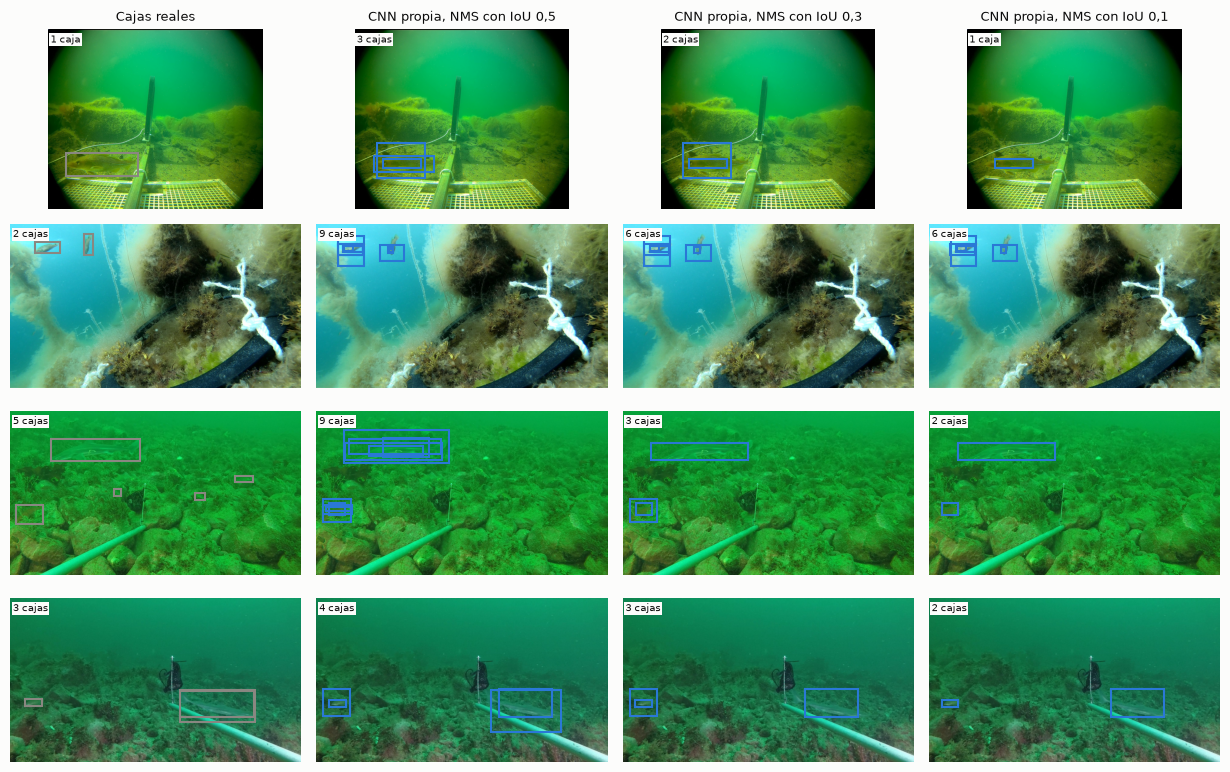

In [38]:
grafico_limites_nms("cnn_propia", "b_limites_nms_cnn.png")

**✍️ Decisión del grupo:** en esta variante se usa el NMS con IoU 0,5 en todos los modelos, en vez del 0,7 del original (9 de noviembre de 2026). Razón: ____.

### ✍️ Análisis de la sección B (completar por el grupo)

-

## C. Mejor modelo para la Parte 3 (ítem 3.2)

La Parte 3 evalúa la robustez del modelo con mejor desempeño. Como referencia, la tabla ordena los modelos por mAP50-95 de validación, porque la elección no debe hacerse con test. Las columnas de test y los FPS son solo de consulta. El criterio final lo fija el grupo abajo.

In [39]:
tabla_mejor_modelo().round(3).round({"FPS": 1})

,mAP50-95 en val,mAP50 en val,mAP50-95 en test,mAP50 en test,FPS
YOLO preentrenado,0.362,0.496,0.342,0.476,93.4
Faster R-CNN,0.324,0.513,0.282,0.433,15.6
YOLO desde cero,0.238,0.426,0.248,0.436,94.1
YOLOv3-tiny a mano preentrenada,0.178,0.388,0.152,0.371,95.8
YOLOv3-tiny a mano,0.148,0.340,0.143,0.380,93.6
CNN propia,0.042,0.124,0.020,0.074,55.9


**✍️ Decisión del grupo:** mejor modelo = ____. Criterio: ____.

### ✍️ Análisis general (completar por el grupo)

-

## 7. Exportación

Guarda las tablas en CSV, sin redondear, junto a las figuras, y el umbral común en `umbral.json`, que `06` comprueba.

In [40]:
tablas = {
    "desempeno_test.csv": tabla_desempeno(TODOS, "test"),
    "desempeno_val.csv": tabla_desempeno(TODOS, "val"),
    "detalle_precision_test.csv": tabla_detalle_precision(TODOS),
    "costo.csv": tabla_costo(TODOS),
    "ap50_por_clase_test.csv": tabla_ap_por_clase(TODOS),
    "ap50_por_frecuencia_test.csv": tabla_por_frecuencia(TODOS),
    "mejor_modelo.csv": tabla_mejor_modelo(),
    "umbral_val_F1.csv": tabla_f1,
    "solape_cajas_val.csv": tabla_solape_val,
    "limites_nms_val.csv": tabla_nms_val,
}
for nombre, tabla in tablas.items():
    tabla.to_csv(DIR_SALIDA / nombre)
pd.concat(curvas_umbral, names=["modelo"]).to_csv(DIR_SALIDA / "umbral_val_curvas.csv")
(DIR_SALIDA / "umbral.json").write_text(json.dumps({"umbral_confianza": UMBRAL_CONFIANZA}), encoding="utf-8")
print(f"Umbral común usado: {UMBRAL_CONFIANZA}")
print(f"Archivos en {DIR_SALIDA.relative_to(RAIZ)}:", *sorted(p.name for p in DIR_SALIDA.iterdir()), sep="\n  ")

Umbral común usado: 0.25
Archivos en resultados\comparacion:
  a_ap_por_clase.png
  a_curva_pr.png
  a_curvas_val.png
  a_desempeno.png
  a_ejemplos.png
  ap50_por_clase_test.csv
  ap50_por_frecuencia_test.csv
  b_ap_por_clase.png
  b_curva_pr.png
  b_curvas_val.png
  b_desempeno.png
  b_ejemplos.png
  b_limites_nms_cnn.png
  b_mAP_tiempo_FPS.png
  costo.csv
  desempeno_test.csv
  desempeno_val.csv
  detalle_precision_test.csv
  limites_nms_val.csv
  mejor_modelo.csv
  solape_cajas_val.csv
  umbral.json
  umbral_val.png
  umbral_val_F1.csv
  umbral_val_curvas.csv


## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).